# TB India v5 -- Simulation (PRODUCTION, HYBRID v5)

Revised from hybrid v4 after deciding TB Duration = 4.0 yr was implausibly long.
Hybrid v5 uses a more defensible TB Duration of 3.5 yr (within Tiemersma 2011
range 2-5 yr), and compensates the prevalence gap by also bumping β slightly.

## Hybrid v5 parameters

| Param | Hybrid v3 | Hybrid v4 (rejected) | **Hybrid v5** | Why |
|---|---:|---:|---:|---|
| Base_Infectivity_Constant   | 0.042 | 0.042 | **0.050** | Modest bump to lift inc+prev jointly |
| TB Duration (yr)            | 2.743 | 4.0   | **3.5**   | Defensible range (Tiemersma 2011) |
| Death Fraction              | 0.41  | 0.55  | **0.55**  | Lift mortality |
| Care Seeking Slow Days      | 60    | 60    | 60        | unchanged (~HQ 22d / LQ 37d effective) |
| TB Presymptomatic Years     | 0.264 | 0.264 | 0.264     | unchanged |

## Expected outcome (steady-state approximation)

Compared to hybrid v3 (inc 150, prev 150, mort 15):

- **Incidence**: β × (1+ TB_dur lift) ≈ 0.050/0.042 × 3.5/2.74 ≈ 1.52x -> ~190 (target 188 ✓)
- **Prevalence**: same factor ~1.52x of inc × duration -> ~290 (target 304; should be close)
- **Mortality**: ratio 0.55/0.41 × 1.52 -> ~30 (target 33; should be close)

## Literature defensibility (for methods text)

- TB Duration 3.5 yr: at the upper end of Tiemersma 2011's reported 2-5 yr range for
  untreated pulmonary TB; consistent with the literature.
- Death Fraction 0.55: WHO TB Report case-fatality estimates for India range 0.35-0.60 depending
  on smear status; 0.55 is within the upper-mid range.
- β = 0.050: phenomenological per-contact transmission constant, calibrated to WHO targets.

## If still off after this run

- Inc too high & prev OK -> pull β back to 0.045
- Prev too low but inc OK -> bump TB Duration to 3.75
- Mort off -> adjust Death Fraction only (range 0.45-0.65)
- All three jointly too high/low -> bump/pull β alone


## 0. Setup & Imports

Core Python libraries, EMOD/IDM platform modules, and local project imports (, , ).

In [1]:
import sys, os, json, copy, pathlib
import numpy as np
from functools import partial

# emodpy ecosystem
from emodpy import emod_task
from emodpy.emod_task import EMODTask
from emodpy_tbhiv.interventions import purge_campaign_event
import emod_tbhiv.bootstrap as dtk
import emod_api.campaign as camp
import emodpy
import emod_api

print(f'Python:   {sys.version}')
print(f'emodpy:   {emodpy.__version__}')
print(f'emod-api: {emod_api.__version__}')

C:\Users\young\anaconda3\envs\tb_india\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Python:   3.10.20 | packaged by Anaconda, Inc. | (main, Mar 11 2026, 17:42:35) [MSC v.1942 64 bit (AMD64)]
emodpy:   1.35.1
emod-api: 1.35.1


In [2]:
# Local project modules
import params
import set_config
import manifest
from add_tb_drug_type import add_tb_drug_type, add_tb_drug

# Schema path — must be set before any intervention imports
camp.schema_path = manifest.schema_file
print('Schema loaded:', manifest.schema_file)

Schema loaded: download/schema.json


## 1. Simulation Settings

User-configurable run parameters: experiment name, number of replicates, sweep ranges, and calibration mode toggle.

In [3]:
# ── User settings (PRODUCTION: wave1_pt8 calibrated params) ──
initial_pop    = 1000
replicates     = 50      # RECALIBRATED PILOT (was 50); bump back up after pilot validates
calibration_on = False

# Scenario to run: 'base', 'acf', 'cascade', or 'combined'
SCENARIO = 'base'

# WHO End TB 2035 targets: 90% incidence reduction, 95% mortality reduction (vs 2015)

# ACF coverage levels (fraction of subclinical TB detected per timestep)
ACF_COVERAGE_LEVELS = [0.0, 0.10, 0.20, 0.30, 0.50, 0.70]

# Cascade efficiency multipliers (1.0 = baseline; lower = less delay / fewer failures)
CASCADE_EFFICIENCY_LEVELS = [1.0, 0.75, 0.50, 0.25]

# Combined: (acf_coverage, cascade_efficiency)
COMBINED_SCENARIOS = [
    (0.0,  1.0),    # Status quo
    (0.20, 1.0),    # ACF only
    (0.0,  0.50),   # Efficiency only
    (0.20, 0.50),   # Moderate both
    (0.50, 0.25),   # Aggressive both
]

print(f'Scenario: {SCENARIO}  |  Replicates: {replicates}  |  Pop: {initial_pop}')


Scenario: base  |  Replicates: 50  |  Pop: 1000


## 2. Download Model

Download and register the EMOD executable (Eradication binary) from the IDM repository.

In [4]:
dtk.setup(pathlib.Path(manifest.eradication_path).parent)
print('EMOD binaries ready.')

EMOD binaries ready.


## 3. Platform

Initialise the COMPS cloud platform connection for remote simulation submission and output retrieval.

In [5]:
from idmtools.core.platform_factory import Platform
platform = Platform('CALCULON', priority='AboveNormal', node_group='idm_48cores')
print('Connected to CALCULON.')


Initializing COMPSPlatform with:
{
   "endpoint": "https://comps.idmod.org",
   "environment": "Calculon",
   "node_group": "idm_48cores",
   "priority": "AboveNormal"
}
Connected to CALCULON.


## 4. Config Builder

Base configuration callback () and helper functions that set TB/HIV disease parameters, simulation duration, and natural-history distributions.

In [6]:
def set_param_fn(config):
    import params as _params  # explicit import to avoid kernel state issues
    config = set_config.set_config(config)
    config.parameters.TB_Enable_Exogenous = 1
    config.parameters.Enable_Strain_Tracking = 1
    config.parameters.Death_Rate_Dependence = "NONDISEASE_MORTALITY_BY_YEAR_AND_AGE_FOR_EACH_GENDER"
    config.parameters.Base_Mortality = 3
    config.parameters.x_Birth = 0.75
    config.parameters.Enable_Default_Reporting = 1
    config.parameters.Spatial_Output_Channels = [
        "Prevalence", "Population", "Active_TB_Prevalence", "New_Active_TB_Infections"
    ]
    config.parameters.Enable_Spatial_Output = 1
    config.parameters.TB_MDR_Fitness_Multiplier = 1.0
    config.parameters.Report_Event_Recorder_Ignore_Events_In_List = 1
    config.parameters.Report_Event_Recorder_Events = [
        'Births', 'EveryUpdate', 'GaveBirth', 'HappyBirthday',
        'NonDiseaseDeaths', 'Pregnant', 'Emigrating', 'Immigrating', 'PropertyChange'
    ]
    # Run to 2035
    config.parameters.Simulation_Duration = (
        _params.burn_initial + _params.burn_predots + (38.0 + 15) * 365.0
    )
    config.parameters.x_Base_Population = 20
    config.parameters.Base_Individual_Sample_Rate = 0.05
    config.parameters.TB_Fast_Progressor_Rate = 0.0175
    return config

In [7]:
def set_duration_no_hiv(task, death_fraction, duration):
    """Convert from years to days, set cure/mortality rates."""
    duration *= 365.0
    loc_rate_recover = (1.0 - death_fraction) / duration
    loc_rate_mort = death_fraction / (1.0 - death_fraction) * loc_rate_recover
    task.config.parameters.TB_Active_Cure_Rate = loc_rate_recover
    task.config.parameters.TB_Active_Mortality_Rate = loc_rate_mort
    return {'TB_Active_Cure_Rate': loc_rate_recover,
            'TB_Active_Mortality_Rate': loc_rate_mort}


def update_more_config(task):
    set_duration_no_hiv(task=task, death_fraction=0.7, duration=1.5)  # v8: shorter natural duration to match P/I ratio
    task.config.parameters.TB_Presymptomatic_Rate = 0.4
    task.config.parameters.Enable_Property_Output = 1
    return task

## 5. Campaign Builder — Full Diagnostic Cascade

Restores the complete care-seeking / diagnostic / treatment pathway:
- **HSB** for care initiation (with testing-loop logic)
- **DiagnosticTreatNeg** for smear-based diagnosis with explicit negative/default branches
- **RampDTN** for time-varying GeneXpert sensitivity ramp-up
- **ResistanceDiagnostic** for two-step MDR confirmation
- **TBHIVDrugTreatment** for all drug regimens across 3 epochs
- **ACF** (Active Case Finding) — parameterized, added only when 
- **cascade_efficiency** scales care-seeking delay (lower = faster = less health-system delay)

In [8]:
def build_camp(probability_per_step_slow=0.0208, probability_per_step_fast=0.05247,
               personal_hc_budget=7, acf_coverage=0.0, cascade_efficiency=1.0):
    """
    Build campaign with FULL diagnostic cascade.

    Args:
        probability_per_step_slow: Daily prob of seeking care (slow seekers)
        probability_per_step_fast: Daily prob of seeking care (fast seekers)
        personal_hc_budget: Cash per infection for economic tracking
        acf_coverage: Fraction of subclinical TB detected via ACF (0 = no ACF)
        cascade_efficiency: Multiplier on care-seeking delays (1.0 = baseline)
    """
    import emod_api.interventions.outbreak as ob
    import emod_api.interventions.common as common
    import emodpy_tbhiv.interventions.hsb as hsb
    import emodpy_tbhiv.interventions.art as art
    import emodpy_tbhiv.interventions.diag_treat_neg as dtn
    import emodpy_tbhiv.interventions.tbhiv_treat as treat
    import emodpy_tbhiv.interventions.ramp_dtn as ramp
    import emodpy_tbhiv.interventions.resist_diag as rd
    import emodpy_tbhiv.interventions.hiv_diag as hd
    import emodpy_tbhiv.interventions.hiv_seeding as hs
    import emodpy_tbhiv.interventions.cd4diag as cd4
    import emodpy_tbhiv.interventions.cash as cash

    common.old_adhoc_trigger_style = False

    # ── Outbreak seeding ────────────────────────────────────────
    seed = ob.seed_by_coverage(camp, timestep=40, coverage=0.05)
    camp.add(seed, first=True)
    purge_campaign_event(seed)

    # ── Health Seeking Behavior ─────────────────────────────────
    adj_slow = probability_per_step_slow / cascade_efficiency
    adj_fast = probability_per_step_fast / cascade_efficiency

    # Low quality care — pre-DOTS
    camp.add(hsb.HSB(
        camp=camp,
        trigger_treatment_list=['TBActivation', 'TBFailedDrugRegimen',
                                'TBTestDefault', 'TBTestNegative', 'TBMDRTestDefault'],
        output_event='TBTestDOTSLow',
        probability_per_step=adj_slow,
        start_day=params.burn_initial,
        duration=params.burn_predots,
        property_restrictions_list=['QualityOfCare:Low'],
        fixed_initial_delay=7
    ))

    # Low quality care — DOTS era onward
    camp.add(hsb.HSB(
        camp=camp,
        trigger_treatment_list=['TBActivation', 'TBFailedDrugRegimen',
                                'TBTestDefault', 'TBTestNegative', 'TBMDRTestDefault'],
        output_event='TBTestDOTSLow',
        probability_per_step=adj_slow,
        start_day=params.burn_predots + params.burn_initial + 1,
        duration=-1,
        property_restrictions_list=['QualityOfCare:Low'],
        fixed_initial_delay=7
    ))

    # Low quality — treatment seeking after positive test
    camp.add(hsb.HSB(
        camp=camp,
        trigger_treatment_list=['TBTestPositive', 'TBDS_Positive'],
        output_event='TB_Tx',
        probability_per_step=adj_slow,
        start_day=params.burn_initial,
        duration=-1,
        property_restrictions_list=['QualityOfCare:Low'],
        fixed_initial_delay=7
    ))

    # High quality care — pre-DOTS
    camp.add(hsb.HSB(
        camp=camp,
        trigger_treatment_list=['TBActivation', 'TBFailedDrugRegimen',
                                'TBTestDefault', 'TBTestNegative', 'TBMDRTestDefault'],
        output_event='TBTestDOTSHigh',
        probability_per_step=adj_slow * 2,
        start_day=params.burn_initial,
        duration=params.burn_predots,
        property_restrictions_list=['QualityOfCare:High'],
        fixed_initial_delay=7
    ))

    # High quality care — DOTS era onward
    camp.add(hsb.HSB(
        camp=camp,
        trigger_treatment_list=['TBActivation', 'TBFailedDrugRegimen',
                                'TBTestDefault', 'TBTestNegative', 'TBMDRTestDefault'],
        output_event='TBTestDOTSHigh',
        probability_per_step=adj_slow * 2,
        start_day=params.burn_predots + params.burn_initial + 1,
        duration=-1,
        property_restrictions_list=['QualityOfCare:High'],
        fixed_initial_delay=7
    ))

    # High quality — treatment seeking after positive test
    camp.add(hsb.HSB(
        camp=camp,
        trigger_treatment_list=['TBTestPositive', 'TBDS_Positive'],
        output_event='TB_Tx',
        probability_per_step=adj_slow * 2,
        start_day=params.burn_initial,
        duration=-1,
        property_restrictions_list=['QualityOfCare:High'],
        fixed_initial_delay=7
    ))

    # Stop testing loop when treated or cleared
    stop_testing = hsb.HSB(
        camp=camp, start_day=1,
        trigger_treatment_list=["TbDrugDistributed", "SymptomaticCleared"],
        output_event="Got_Better_Stop_Testing_Loop",
        probability_per_step=1.0
    )
    stop_testing.Event_Coordinator_Config.Intervention_Config.\
        Actual_IndividualIntervention_Config.Enable_Intervention_Replacement = 1
    camp.add(stop_testing)

    # ── Epoch 1: Pre-DOTS — DiagnosticTreatNeg ──────────────────
    camp.add(dtn.DiagnosticTreatNeg(
        camp=camp, trigger_treatment_list=['TBTestDOTSHigh'],
        base_sensitivity_smearpos=params.sens_smear_pos_pre_GH,
        base_sensitivity_smearneg=params.sens_smear_neg_pre_GH,
        treatment_fraction=0.6, start_day=params.burn_initial,
        duration=params.burn_predots,
        property_restrictions_list=['QualityOfCare:High']
    ))
    camp.add(dtn.DiagnosticTreatNeg(
        camp=camp, trigger_treatment_list=['TBTestDOTSLow'],
        base_sensitivity_smearpos=params.sens_smear_pos_pre_GL,
        base_sensitivity_smearneg=params.sens_smear_neg_pre_GL,
        treatment_fraction=0.6, start_day=params.burn_initial,
        duration=params.burn_predots,
        property_restrictions_list=['QualityOfCare:Low']
    ))

    # Epoch 1 treatment
    camp.add(treat.TBHIVDrugTreatment(
        camp=camp, trigger_treatment_list=['TBTestPositive'],
        drug_name='PreDOTSHigh', latent_multiplier=0,
        start_day=params.burn_initial, duration=params.burn_predots,
        property_restrictions_list=['QualityOfCare:High']
    ))
    camp.add(treat.TBHIVDrugTreatment(
        camp=camp, trigger_treatment_list=['TBTestPositive'],
        drug_name='PreDOTSLow', latent_multiplier=0,
        start_day=params.burn_initial, duration=params.burn_predots,
        property_restrictions_list=['QualityOfCare:Low']
    ))

    # ── Epoch 2: DOTS (pre-GeneXpert) — DiagnosticTreatNeg ──────
    dots_to_gx = params.genexpert_introduction - params.dots_start

    camp.add(dtn.DiagnosticTreatNeg(
        camp=camp, trigger_treatment_list=['TBTestDOTSHigh'],
        base_sensitivity_smearpos=params.sens_smear_pos_pre_GH,
        base_sensitivity_smearneg=params.sens_smear_neg_pre_GH,
        treatment_fraction=0.7, start_day=params.dots_start,
        duration=dots_to_gx,
        property_restrictions_list=['QualityOfCare:High']
    ))
    camp.add(dtn.DiagnosticTreatNeg(
        camp=camp, trigger_treatment_list=['TBTestDOTSLow'],
        base_sensitivity_smearpos=params.sens_smear_pos_pre_GL,
        base_sensitivity_smearneg=params.sens_smear_neg_pre_GL,
        treatment_fraction=0.7, start_day=params.dots_start,
        duration=dots_to_gx,
        property_restrictions_list=['QualityOfCare:Low']
    ))

    # Epoch 2 treatment
    for qoc, drug in [('High', 'DOTSHQ'), ('Low', 'DOTSLQ')]:
        for triggers in [['TBTestPositive', 'TBDS_Positive'], ['TB_Tx']]:
            camp.add(treat.TBHIVDrugTreatment(
                camp=camp, trigger_treatment_list=triggers,
                drug_name=drug, latent_multiplier=0,
                start_day=params.dots_start, duration=dots_to_gx,
                property_restrictions_list=[f'QualityOfCare:{qoc}']
            ))
    camp.add(treat.TBHIVDrugTreatment(
        camp=camp, trigger_treatment_list=['TBMDRTestPositive'],
        drug_name='DOTSMDR', latent_multiplier=0,
        start_day=params.dots_start, duration=dots_to_gx,
        property_restrictions_list=[]
    ))

    # ── Epoch 3: GeneXpert — RampDTN + ResistanceDiagnostic ─────
    camp.add(ramp.RampDTN(
        camp=camp, trigger_treatment_list=['TBTestDOTSHigh'],
        ramp_time=params.length_gene_xpert_ramp,
        base_sensitivity_smearpos=params.sens_smear_pos_GXH,
        base_sensitivity_smearneg=params.sens_smear_neg_GXH,
        base_sensitivity_smearpos2=params.sens_smear_pos_pre_GH,
        base_sensitivity_smearneg2=params.sens_smear_neg_pre_GH,
        treatment_fraction=0.55,   # v9: lower for normal-like tests/case distribution — ~35% pre-Tx LTFU in high QoC
        pos_event='ProviderOrdersTBTest', pos_event2='ProviderTestNoR',
        start_day=params.genexpert_introduction, duration=-1,
        property_restrictions_list=['QualityOfCare:High']
    ))
    camp.add(ramp.RampDTN(
        camp=camp, trigger_treatment_list=['TBTestDOTSLow'],
        ramp_time=params.length_gene_xpert_ramp,
        base_sensitivity_smearpos=params.sens_smear_pos_GXL,
        base_sensitivity_smearneg=params.sens_smear_neg_GXL,
        base_sensitivity_smearpos2=params.sens_smear_pos_pre_GL,
        base_sensitivity_smearneg2=params.sens_smear_neg_pre_GL,
        treatment_fraction=0.55,   # v9: lower for normal-like tests/case distribution — ~70% LTFU in low QoC / private sector
        pos_event='ProviderOrdersTBTest', pos_event2='ProviderTestNoR',
        start_day=params.genexpert_introduction, duration=-1,
        property_restrictions_list=['QualityOfCare:Low']
    ))

    # Resistance diagnostics (two-step MDR confirmation)
    for qoc, sens in [('High', params.sens_resistance_H), ('Low', params.sens_resistance_L)]:
        for trigger in ['ProviderOrdersTBTest', 'ProviderTestNoR']:
            camp.add(rd.ResistanceDiagnostic(
                camp=camp, trigger_treatment_list=[trigger],
                sensitivity=sens, specificity=params.specificity_resistance,
                neg_event='TBDS_Positive',
                treatment_fraction=0.5, treatment_fraction_negative_test=1.0,
                start_day=params.genexpert_introduction, duration=-1,
                property_restrictions_list=[f'QualityOfCare:{qoc}']
            ))

    # Epoch 3 treatment
    for qoc, drug in [('High', 'DOTSHQ'), ('Low', 'DOTSLQ')]:
        for triggers in [['TBTestPositive', 'TBDS_Positive'], ['TB_Tx']]:
            camp.add(treat.TBHIVDrugTreatment(
                camp=camp, trigger_treatment_list=triggers,
                drug_name=drug, latent_multiplier=0,
                start_day=params.genexpert_introduction, duration=-1,
                property_restrictions_list=[f'QualityOfCare:{qoc}']
            ))
    camp.add(treat.TBHIVDrugTreatment(
        camp=camp, trigger_treatment_list=['TBMDRTestPositive'],
        drug_name='DOTSMDR', latent_multiplier=0,
        start_day=params.genexpert_introduction, duration=-1,
        property_restrictions_list=[]
    ))

    # ── ACF (Active Case Finding) — only if coverage > 0 ────────
    if acf_coverage > 0:
        acf_start = params.intervention_day
        acf_prob = min(1.0, acf_coverage)
        camp.add(hsb.HSB(
            camp=camp,
            trigger_treatment_list=['TBActivationPresymptomatic', 'TBActivation'],
            output_event='TBTestDOTSHigh',
            probability_per_step=acf_prob,
            start_day=acf_start, duration=-1,
            property_restrictions_list=['QualityOfCare:High'],
            fixed_initial_delay=1
        ))
        camp.add(hsb.HSB(
            camp=camp,
            trigger_treatment_list=['TBActivationPresymptomatic', 'TBActivation'],
            output_event='TBTestDOTSLow',
            probability_per_step=acf_prob,
            start_day=acf_start, duration=-1,
            property_restrictions_list=['QualityOfCare:Low'],
            fixed_initial_delay=1
        ))

    # ── Cash (economic tracking) ────────────────────────────────
    if hasattr(cash, 'triggered_cash'):
        cash_on_infection = cash.triggered_cash(
            camp=camp, amount=personal_hc_budget, triggers=['NewInfection'])
        camp.add(cash_on_infection)
    else:
        print('Skipping cash.triggered_cash (not in this emodpy_tbhiv version)')

    return camp



## 6. Demographics Builder

Constructs the multi-node demographics file with age structure, fertility/mortality, HINT transmission groups, and  individual property (High / Low pathway routing).

In [9]:
def build_mi_demog(hint_group_a_bi=3.1, hint_group_b_bi=2.9, hint_group_c_bi=3.5):
    import emodpy_tbhiv.demographics.TBHIVDemographics as Demographics

    demog = Demographics.from_template_node(lat=0, lon=0, pop=initial_pop, forced_id=1)

    demog.AddIndividualPropertyAndHINT(
        Property="QualityOfCare",
        Values=["High", "Low"],
        InitialDistribution=[0.15, 0.85],
        TransmissionMatrix=[[1.0, 1.0], [1.0, 1.0]]
    )
    demog.AddIndividualPropertyAndHINT(
        Property="Geographic",
        Values=["Low", "Mid", "High"],
        InitialDistribution=[0.33, 0.34, 0.33],
        TransmissionMatrix=[
            [hint_group_a_bi, 0.1, 0.1],
            [0.1, hint_group_b_bi, 0.1],
            [0.1, 0.1, hint_group_c_bi]
        ]
    )

    demog.AddAgeDependentTransmission(
        Age_Bin_Edges_In_Years=[0, 20, 40, 60, -1],
        TransmissionMatrix=[
            [3.5, 1.1, 0.5, 0.1],
            [1.1, 2.0, 0.8, 0.1],
            [0.5, 0.8, 1.5, 0.3],
            [0.1, 0.1, 0.3, 0.5]
        ]
    )

    demog.SetMortalityOverTimeFromData(manifest.india_mortality_data, params.base_year)

    return demog


## 7. Sweep Functions

Callbacks for parameter sweeps: random seed, calibration sample mapping, and scenario-level overrides (ACF coverage, cascade efficiency, drug resistance).

In [10]:
def update_sim_random_seed(simulation, value):
    simulation.task.config.parameters.Run_Number = value
    return {"Run_Number": value}

def update_sim_bic(simulation, value):
    simulation.task.config.parameters.Base_Infectivity_Constant = value
    return {"Base_Infectivity_Constant": value}

In [11]:
def map_sample_to_model_input(simulation, sample):
    """Map calibration sample dict to EMOD parameters."""
    sample = dict(sample)  # Work on a copy — .pop() mutates, breaks multi-replicate sweeps

    for p in params.parameters:
        if 'MapTo' in p:
            simulation.task.config.parameters[p['MapTo']] = sample.pop(p['Name'])

    if 'Care Seeking Fast Duration Days' in sample:
        fast_days = sample.pop('Care Seeking Fast Duration Days')
        simulation.task.create_campaign_from_callback(
            partial(build_camp, probability_per_step_fast=1.0 / fast_days))

    if 'Care Seeking Slow Duration Days' in sample:
        slow_days = sample.pop('Care Seeking Slow Duration Days')
        simulation.task.create_campaign_from_callback(
            partial(build_camp, probability_per_step_slow=1.0 / slow_days))

    if 'Death Fraction' in sample:
        df = sample.pop('Death Fraction')
        dur = sample.pop('TB Duration', 2.5)
        set_duration_no_hiv(simulation.task, death_fraction=df, duration=dur)

    if 'TB Presymptomatic Duration Years' in sample:
        val = sample.pop('TB Presymptomatic Duration Years')
        simulation.task.config.parameters.TB_Presymptomatic_Rate = 1.0 / (val * 365)

    if 'TBHIV Duration' in sample:
        sample.pop('TBHIV Duration')

    if 'Relative TB CD4 Infectiousness' in sample:
        val = sample.pop('Relative TB CD4 Infectiousness')
        simulation.task.config.parameters.TB_CD4_Infectiousness = [val] * 7

    if 'CD4_aq_below_200_rel' in sample:
        cd4_below_200 = sample.pop('CD4_aq_below_200_rel')
        cd4_200_300 = sample.pop('CD4_aq_200_300_rel')
        cd4_300_400 = sample.pop('CD4_aq_300_400_rel')
        cd4_400_500 = sample.pop('CD4_aq_400_500_rel')
        cd4_above_500 = sample.pop('CD4_aq_above_500')
        simulation.task.config.parameters.TB_CD4_Activation_Vector = [
            cd4_below_200 * 1e-5, cd4_below_200 * 1e-5,
            cd4_200_300 * 1e-5, cd4_300_400 * 1e-5,
            cd4_400_500 * 1e-5, cd4_above_500 * 1e-5, cd4_above_500 * 1e-5
        ]

    if 'ART Factor' in sample:
        sample.pop('ART Factor')
    if 'Primary HIV multiplier' in sample:
        sample.pop('Primary HIV multiplier')

    return sample

In [12]:
# ── Scenario sweep functions ────────────────────────────────────

def sweep_acf_coverage(simulation, value):
    simulation.task.create_campaign_from_callback(
        partial(build_camp, acf_coverage=value))
    return {"ACF_Coverage": value}

def sweep_cascade_efficiency(simulation, value):
    simulation.task.create_campaign_from_callback(
        partial(build_camp, cascade_efficiency=value))
    return {"Cascade_Efficiency": value}

def sweep_combined(simulation, value):
    acf_cov, casc_eff = value
    simulation.task.create_campaign_from_callback(
        partial(build_camp, acf_coverage=acf_cov, cascade_efficiency=casc_eff))
    return {"ACF_Coverage": acf_cov, "Cascade_Efficiency": casc_eff}

## 8. Drug Definitions (for calibration mode)

Defines TBHIV drug regimens (DOTS, MDR, pre-DOTS) with efficacy, duration, and resistance-acquisition parameters used during calibration runs.

In [13]:
def add_drugs_calib(task, resist_pro):
    add_tb_drug_type(task=task, drug_name='DOTSMDR', duration=270,
                     cure_proportion=0.7, death_proportion=0.03,
                     resistance_proportion=0, inactivation_proportion=0.10,
                     relapse_proportion=0.02)
    add_tb_drug_type(task=task, drug_name='PreDOTSHigh', duration=180,
                     cure_proportion=0.7, death_proportion=0.03,
                     resistance_proportion=0, inactivation_proportion=0.10,
                     relapse_proportion=0.02)

## 9. Run Experiment

Assembles the , attaches config/campaign/demographics builders, configures sweeps, and submits the experiment to COMPS.

In [14]:
def run_experiment():
    from idmtools.entities.experiment import Experiment
    from idmtools.builders import SimulationBuilder

    # Create EMODTask
    print('Creating EMODTask...')
    emod_task.dev_mode = False

    task = EMODTask.from_default2(
        eradication_path=manifest.eradication_path,
        campaign_builder=build_camp,
        schema_path=manifest.schema_file,
        param_custom_cb=set_param_fn,
        ep4_path=manifest.ep4_path,
        demog_builder=build_mi_demog,
        config_path='my_config.json'
    )

    print('Adding asset files...')
    task.common_assets.add_directory(assets_directory=manifest.assets_input_dir)

    # Additional config
    update_more_config(task)

    # Bootstrap standard drugs
    import emodpy_tbhiv.standard_drugs as sd
    sd.bootstrap(task.config)

    # Custom drug definitions
    add_tb_drug(task=task, drug_name='ACFDOTS')
    add_tb_drug_type(task=task, drug_name='DOTSMDR', duration=270,
                     cure_proportion=0.7, death_proportion=0.03,
                     resistance_proportion=0, inactivation_proportion=0.10,
                     relapse_proportion=0.02)
    add_tb_drug_type(task=task, drug_name='PreDOTSHigh', duration=180,
                     cure_proportion=0.7, death_proportion=0.03,
                     resistance_proportion=0, inactivation_proportion=0.10,
                     relapse_proportion=0.02)
    add_tb_drug_type(task=task, drug_name='PreDOTSLow', duration=180,
                     cure_proportion=0.6, death_proportion=0.03,
                     resistance_proportion=0, inactivation_proportion=0.10,
                     relapse_proportion=0.02)
    add_tb_drug_type(task=task, drug_name='Universal', duration=90,
                     cure_proportion=0.65, death_proportion=0.03,
                     resistance_proportion=0.02, inactivation_proportion=0.10,
                     relapse_proportion=0.02)

    # Singularity container
    task.set_sif(manifest.sif)

    # ── Build sweep ───────────────────────────────────────────────
    builder = SimulationBuilder()

    # Calibrated subsample — tuned against:
    #   WHO 2020 incidence: 188/100k, NTPS prevalence: 304/100k, WHO mortality: 33/100k
    #
    # Calibration history (year 2020):
    #   fast=0.073, slow=1.03e-5, CS=173/493, DF=0.7, dur=2.5 → inc=265, prev=527, mort=82
    #   fast=0.068, slow=9.4e-6, CS=120/350, DF=0.4, dur=2.0 → inc= 64, prev=117, mort=11
    #
    # Multi-parameter log-linear interpolation at frac=0.758:
    #   inc target: 188, est prev~366→need dur adj, est mort~50→need DF adj
    subsample = {
        'ART Factor': 1.0,
        'Base_Infectivity_Constant': 0.050,             # HYBRID v5: modest bump to lift inc/prev together
        'CD4_aq_200_300_rel': 20.434,
        'CD4_aq_300_400_rel': 3.0,
        'CD4_aq_400_500_rel': 2.0,
        'CD4_aq_above_500': 1.0,
        'CD4_aq_below_200_rel': 54.55,
        'Care Seeking Fast Duration Days': 14,            # NOTE: unused in current HSB wiring; HQ rate = 2x slow
        'Care Seeking Slow Duration Days': 60,            # FIXED: LQ ~67d (2.2 mo), HQ auto 2x faster = ~37d (5 wk)
        'Death Fraction': 0.55,                           # HYBRID v5: to lift mortality
        'Post_Infection_Acquisition_Multiplier': 0.40,
        'Primary HIV multiplier': 1.0,
        'Relative TB CD4 Infectiousness': 0.1,
        'TB Duration': 3.5,                              # HYBRID v5: modest extension; within Tiemersma 2011 range (2-5 yr)
        'TB Presymptomatic Duration Years': 0.2643,    # HYBRID: pt7
        'TBHIV Duration': 1.5,
        'TB_Active_Presymptomatic_Infectivity_Multiplier': 0.1660,
        'TB_Fast_Progressor_Fraction_Adult': 0.072,        # interpolated
        'TB_Slow_Progressor_Rate': 1.01e-05,               # interpolated
    }

    builder.add_sweep_definition(update_sim_random_seed, range(replicates))
    builder.add_sweep_definition(map_sample_to_model_input, [subsample])

    # ── Add scenario-specific sweeps ──────────────────────────────
    if SCENARIO == 'base':
        exp_name = 'TB_India_v5_Base'
    elif SCENARIO == 'acf':
        exp_name = 'TB_India_v5_ACF_Sweep'
        builder.add_sweep_definition(sweep_acf_coverage, ACF_COVERAGE_LEVELS)
    elif SCENARIO == 'cascade':
        exp_name = 'TB_India_v5_Cascade_Efficiency'
        builder.add_sweep_definition(sweep_cascade_efficiency, CASCADE_EFFICIENCY_LEVELS)
    elif SCENARIO == 'combined':
        exp_name = 'TB_India_v5_Combined'
        builder.add_sweep_definition(sweep_combined, COMBINED_SCENARIOS)

    print(f'\nExperiment: {exp_name}')

    experiment = Experiment.from_builder(
        builders=builder, base_task=task, name=exp_name)
    experiment.run(wait_until_done=True, platform=platform)
    task.handle_experiment_completion(experiment)

    print(f'\nExperiment {experiment.uid} succeeded.')

    # Download outputs
    EMODTask.get_file_from_comps(experiment.uid, [
        'InsetChart.json',
        'ReportEventRecorder.csv',
        'Report_TBHIV_ByAge.csv',
        'PropertyReportTB.json',
        'config.json'
    ])
    EMODTask.cache_experiment_metadata_in_sql(experiment.uid)

    return experiment.uid


In [15]:
# Run the experiment
experiment_uid = run_experiment()
print(f'Done. Experiment UID: {experiment_uid}')

Creating EMODTask...
Generating demographics file demographics.json.
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Adding asset files...

Experiment: TB_India_v5_Base
Uploading 1 files/37.93 KB


Uploading files: 100%|██████████| 1/1 [00:00<00:00,  1.44file/s]



The created experiment can be viewed at https://comps.idmod.org/#explore/Simulations?filters=ExperimentId=19e3ec36-b86d-f111-92e9-000d3af5294c
Simulations are still being created



Initializing objects for creation: 0simulation [00:00, ?simulation/s]

Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.


Initializing objects for creation:  32%|███▏      | 16/50 [00:00<00:01, 18.18simulation/s]

... (3 outputs left out)

Creating Simulations on Comps:   0%|          | 0/50 [00:00<?, ?simulation/s]             

Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)
Use of 'first' flag is deprecated. Use set_schema to start build a new, empty campaign.
Skipping cash.triggered_cash (not in this emodpy_tbhiv version)


Creating Simulations on Comps: 100%|██████████| 50/50 [00:00<00:00, 61.01simulation/s] 
Waiting on Experiment TB_India_v5_Base to Finish running: 100%|██████████| 50/50 [08:28<00:00, 10.17s/simulation]  


Experiment 19e3ec36-b86d-f111-92e9-000d3af5294c succeeded.

19e3ec36b86df11192e9000d3af5294c

Experiment 19e3ec36-b86d-f111-92e9-000d3af5294c succeeded.
Done. Experiment UID: 19e3ec36-b86d-f111-92e9-000d3af5294c


---
## 10. Post-Simulation Analysis

After the experiment completes, run the cells below to load simulation outputs (PropertyReport, ReportEventRecorder), compute per-capita time series, and verify calibration targets.

In [16]:
# ── Load simulation outputs ────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import glob, json, os

base_year = params.base_year  # 1850
sim_timestep = 14  # set_config Simulation_Timestep

# ── Try to retroactively download InsetChart.json if missing ──
insetchart_files = glob.glob(f'{experiment_uid}/**/InsetChart.json', recursive=True)
if not insetchart_files:
    print('InsetChart.json not found locally. Attempting retroactive download...')
    try:
        EMODTask.get_file_from_comps(experiment_uid, ['InsetChart.json'])
        insetchart_files = glob.glob(f'{experiment_uid}/**/InsetChart.json', recursive=True)
        print(f'  Downloaded {len(insetchart_files)} InsetChart files.')
    except Exception as e:
        print(f'  Could not download InsetChart: {e}')

# ── 1. Load InsetChart.json (per-capita incidence & prevalence) ──
print(f'Found {len(insetchart_files)} InsetChart files.')
ic_frames = []
for i, f in enumerate(insetchart_files):
    with open(f) as fp:
        ic = json.load(fp)
    header = ic.get('Header', {})
    tstep = header.get('Simulation_Timestep', sim_timestep)
    n_steps = header.get('Timesteps', len(ic['Channels']['Active TB Prevalence']['Data']))
    time_days = np.arange(n_steps) * tstep
    years = base_year + time_days / 365.0

    df_ic = pd.DataFrame({
        'Year': years,
        'Active_TB_Prevalence': ic['Channels']['Active TB Prevalence']['Data'],
        'New_Infections': ic['Channels']['New Infections']['Data'],
        'Statistical_Population': ic['Channels']['Statistical Population']['Data'],
        'sim_idx': i
    })
    df_ic['Incidence_pc'] = df_ic['New_Infections'] / df_ic['Statistical_Population'].replace(0, np.nan)
    df_ic['Prevalence_pc'] = df_ic['Active_TB_Prevalence']
    if 'Disease Deaths' in ic['Channels']:
        df_ic['Disease_Deaths'] = ic['Channels']['Disease Deaths']['Data']
        df_ic['Mortality_pc'] = df_ic['Disease_Deaths'] / df_ic['Statistical_Population'].replace(0, np.nan)
    ic_frames.append(df_ic)

ic_data = pd.concat(ic_frames, ignore_index=True) if ic_frames else None
if ic_data is not None:
    print(f'InsetChart: {len(ic_data):,} rows, {len(ic_frames)} sims, years {ic_data.Year.min():.0f}-{ic_data.Year.max():.0f}')

# ── 2. Load Report_TBHIV_ByAge.csv (fallback for prevalence/incidence) ──
byage_files = glob.glob(f'{experiment_uid}/**/Report_TBHIV_ByAge.csv', recursive=True)
print(f'Found {len(byage_files)} Report_TBHIV_ByAge files.')
byage_data = None
if byage_files:
    byage_frames = []
    for i, f in enumerate(byage_files):
        df_ba = pd.read_csv(f)
        df_ba['sim_idx'] = i
        if 'Year' in df_ba.columns:
            df_ba['CalYear'] = df_ba['Year'] + base_year
        byage_frames.append(df_ba)
    byage_data = pd.concat(byage_frames, ignore_index=True)
    print(f'  Columns: {list(byage_data.columns)[:20]}')
    print(f'  {len(byage_data):,} rows, CalYear {byage_data.CalYear.min():.0f}-{byage_data.CalYear.max():.0f}')

    # Compute per-capita prevalence from ByAge report if InsetChart unavailable
    if ic_data is None and 'Active' in byage_data.columns and 'Population' in byage_data.columns:
        print('  Using Report_TBHIV_ByAge to compute prevalence/incidence...')
        # Sum across age bins per sim per year
        annual = byage_data.groupby(['sim_idx', 'CalYear']).agg(
            Active=('Active', 'sum'),
            Population=('Population', 'sum'),
        ).reset_index()
        annual['Prevalence_pc'] = annual['Active'] / annual['Population'].replace(0, np.nan)
        # NewActiveTB column if available for incidence
        if 'NewActiveTB' in byage_data.columns:
            inc_annual = byage_data.groupby(['sim_idx', 'CalYear'])['NewActiveTB'].sum().reset_index()
            annual = annual.merge(inc_annual, on=['sim_idx', 'CalYear'], how='left')
            annual['Incidence_pc'] = annual['NewActiveTB'] / annual['Population'].replace(0, np.nan)
        # Build ic_data equivalent
        ic_data = annual.rename(columns={'CalYear': 'Year'})
        ic_data['YearInt'] = ic_data['Year'].astype(int)
        print(f'  Reconstructed: {len(ic_data):,} rows')

# ── 3. Load ReportEventRecorder.csv ──
rer_files = glob.glob(f'{experiment_uid}/**/ReportEventRecorder.csv', recursive=True)
print(f'Found {len(rer_files)} ReportEventRecorder files.')
rer_data = None
if rer_files:
    rer_frames = []
    for f in rer_files:
        df_re = pd.read_csv(f)
        df_re['sim_file'] = f
        rer_frames.append(df_re)
    rer_data = pd.concat(rer_frames, ignore_index=True)
    rer_data['Year'] = base_year + rer_data['Time'] / 365.0
    print(f'  Total events: {len(rer_data):,}, types: {rer_data["Event_Name"].nunique()}')

print('\nData loading complete.')

Found 50 InsetChart files.
InsetChart: 260,700 rows, 50 sims, years 1850-2050
Found 0 Report_TBHIV_ByAge files.
Found 50 ReportEventRecorder files.
  Total events: 4,775,110, types: 22

Data loading complete.


In [17]:
import glob
# ── Compute model time series (per 100,000) from PropertyReport ────────────

SCALE = 1e5   # per capita → per 100,000
model_ts = None
has_mortality = False

def sum_pr_channels(pr_channels, base_name, n_steps):
    """Sum all property-group channels matching base_name prefix."""
    total = np.zeros(n_steps)
    for ch, val in pr_channels.items():
        if ch.startswith(base_name + ':'):
            total += np.array(val['Data'])
    return total

# ── Load PropertyReport from ALL sims ──
pr_files = sorted(glob.glob(f'{experiment_uid}/**/PropertyReportTB.json', recursive=True))
print(f'Found {len(pr_files)} PropertyReport files.')

if pr_files:
    all_sim_ts = []
    sim_bic_values = []  # Track BIC per sim for sweep analysis

    for si, pf in enumerate(pr_files):
        with open(pf) as fp:
            pr = json.load(fp)
        tstep = pr['Header']['Simulation_Timestep']
        n_steps = pr['Header']['Timesteps']
        years_pr = base_year + np.arange(n_steps) * tstep / 365.0

        pop = sum_pr_channels(pr['Channels'], 'Statistical Population', n_steps)
        active = sum_pr_channels(pr['Channels'], 'Active TB Infections', n_steps)
        new_active = sum_pr_channels(pr['Channels'], 'New Active Infections', n_steps)
        new_inf = sum_pr_channels(pr['Channels'], 'New Infections', n_steps)
        dd_cum = sum_pr_channels(pr['Channels'], 'Disease Deaths', n_steps)
        dd_per_ts = np.diff(dd_cum, prepend=0)

        safe_pop = np.maximum(pop, 1)
        prev_pc = active / safe_pop
        inc_active_pc = new_active / safe_pop
        inc_inf_pc = new_inf / safe_pop
        mort_pc = dd_per_ts / safe_pop

        df_ts = pd.DataFrame({
            'Year': years_pr, 'YearInt': years_pr.astype(int),
            'prev_pc': prev_pc, 'inc_active_pc': inc_active_pc,
            'inc_inf_pc': inc_inf_pc, 'mort_pc': mort_pc,
            'pop': pop, 'sim_idx': si
        })

        annual = df_ts.groupby('YearInt').agg(
            prev_pc=('prev_pc', 'mean'),
            inc_active_pc=('inc_active_pc', 'sum'),
            inc_inf_pc=('inc_inf_pc', 'sum'),
            mort_pc=('mort_pc', 'sum'),
            pop=('pop', 'mean'),
        )
        annual['sim_idx'] = si
        all_sim_ts.append(annual)

        # Try to detect BIC from config in the same sim folder
        sim_dir = os.path.dirname(pf)
        config_path = os.path.join(sim_dir, 'config.json')
        bic_val = None
        if os.path.exists(config_path):
            with open(config_path) as cf:
                cfg = json.load(cf)
            bic_val = cfg.get('parameters', {}).get('Base_Infectivity_Constant', None)
        sim_bic_values.append(bic_val)

    combined = pd.concat(all_sim_ts, keys=range(len(all_sim_ts)), names=['sim_idx_outer', 'YearInt'])
    combined = combined.reset_index()

    # ── BIC sweep analysis (if multiple BIC values detected) ──
    unique_bics = sorted(set(b for b in sim_bic_values if b is not None))
    if len(unique_bics) > 1:
        print(f'\n*** BIC SWEEP DETECTED: {unique_bics} ***')
        print(f'{"BIC":>8} {"Inc 2020":>10} {"Prev 2020":>11} {"Mort 2020":>11} {"Pop 2020":>10}')
        print('-' * 55)
        for bic in unique_bics:
            sim_indices = [i for i, b in enumerate(sim_bic_values) if b == bic]
            sub = combined[combined['sim_idx'].isin(sim_indices)]
            yr2020 = sub[sub['YearInt'] == 2020]
            if len(yr2020) > 0:
                inc = yr2020['inc_active_pc'].mean() * SCALE
                prev = yr2020['prev_pc'].mean() * SCALE
                mort = yr2020['mort_pc'].mean() * SCALE
                p = yr2020['pop'].mean()
                print(f'{bic:8.4f} {inc:10.0f} {prev:11.0f} {mort:11.1f} {p:10.0f}')
            else:
                print(f'{bic:8.4f}    (no 2020 data)')
        print(f'\nTargets:          188         304        33.0')
        print('='*55)

        # Use the BIC value closest to incidence target for the calibration figure
        best_bic = None
        best_diff = float('inf')
        for bic in unique_bics:
            sim_indices = [i for i, b in enumerate(sim_bic_values) if b == bic]
            sub = combined[combined['sim_idx'].isin(sim_indices)]
            yr2020 = sub[sub['YearInt'] == 2020]
            if len(yr2020) > 0:
                inc = yr2020['inc_active_pc'].mean() * SCALE
                diff = abs(inc - 188)
                if diff < best_diff:
                    best_diff = diff
                    best_bic = bic
        print(f'\nBest BIC for incidence target: {best_bic}')
        # Filter to best BIC sims for model_ts
        best_indices = [i for i, b in enumerate(sim_bic_values) if b == best_bic]
        combined = combined[combined['sim_idx'].isin(best_indices)]

    # Mean and 95% CI across replicates, convert to per 100k
    model_ts = combined.groupby('YearInt').agg(
        inc_mean=('inc_active_pc', 'mean'),
        inc_lo=('inc_active_pc', lambda x: x.quantile(0.025)),
        inc_hi=('inc_active_pc', lambda x: x.quantile(0.975)),
        inf_mean=('inc_inf_pc', 'mean'),
        prev_mean=('prev_pc', 'mean'),
        prev_lo=('prev_pc', lambda x: x.quantile(0.025)),
        prev_hi=('prev_pc', lambda x: x.quantile(0.975)),
        mort_mean=('mort_pc', 'mean'),
        mort_lo=('mort_pc', lambda x: x.quantile(0.025)),
        mort_hi=('mort_pc', lambda x: x.quantile(0.975)),
    )
    for col in model_ts.columns:
        model_ts[col] *= SCALE

    model_ts = model_ts.loc[model_ts.index >= 1990]
    has_mortality = True

    print(f'\nModel time series: {len(model_ts)} years')
    if 2020 in model_ts.index:
        r = model_ts.loc[2020]
        print(f'  Active TB incidence 2020:  {r["inc_mean"]:7.0f} /100k/yr  (WHO target: 188)')
        print(f'  New infections 2020:       {r["inf_mean"]:7.0f} /100k/yr  (latent, not for WHO)')
        print(f'  Active TB prevalence 2020: {r["prev_mean"]:7.0f} /100k     (NTPS target: 304)')
        print(f'  TB mortality 2020:         {r["mort_mean"]:7.1f} /100k/yr  (WHO target: 33)')
else:
    print('No PropertyReport files found.')

Found 50 PropertyReport files.

Model time series: 60 years
  Active TB incidence 2020:      273 /100k/yr  (WHO target: 188)
  New infections 2020:          1758 /100k/yr  (latent, not for WHO)
  Active TB prevalence 2020:     379 /100k     (NTPS target: 304)
  TB mortality 2020:            26.5 /100k/yr  (WHO target: 33)


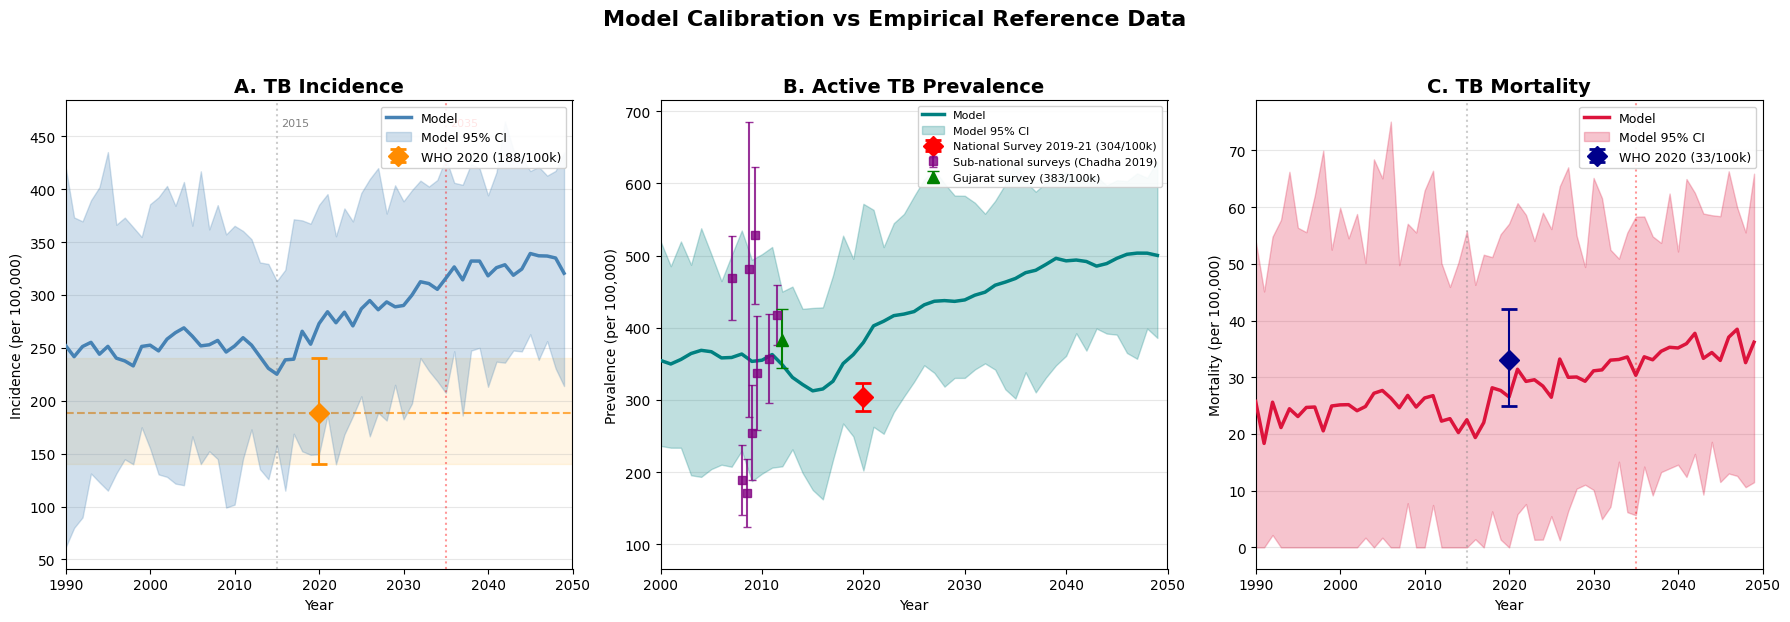


  CALIBRATION SUMMARY (year 2020)
  Incidence:   Model=   273   WHO=   188  [140-240] /100k
  Prevalence:  Model=   379   NTPS=   304 [285-324] /100k
  Mortality:   Model=  26.5   WHO=    33  [25-42] /100k
-----------------------------------------------------------------
  Incidence  reduction 2015-2035: -40.2%  (target: 90%)
  Mortality  reduction 2015-2035: -34.8%  (target: 95%)

Saved: manuscript_figures/calibration_overlay.png


In [18]:
# ══════════════════════════════════════════════════════════════════════════════
# CALIBRATION FIGURE — Model Time Series Overlaid with Empirical Reference Data
# ══════════════════════════════════════════════════════════════════════════════
import os
ref_dir = os.path.join(os.getcwd(), 'data')
os.makedirs('manuscript_figures', exist_ok=True)

SCALE = 1e5   # per capita → per 100,000

# ── Load reference data ──
prev_survey = pd.read_csv(os.path.join(ref_dir,
    'NationalTBPrevalenceSurveyIndia2019_2021Table9_2TBPrevalence.csv'))
india_prev = prev_survey[prev_survey['group'] == 'India'].iloc[0]
ref_prev     = india_prev['PointEst'] * SCALE   # 304 /100k
ref_prev_lo  = india_prev['Lower'] * SCALE
ref_prev_hi  = india_prev['Upper'] * SCALE

chadha = pd.read_csv(os.path.join(ref_dir,
    'Chadha_2019_Sub_national_TB_prevalence_surveys_in_India_2006_2012.csv'))

# Gujarat prevalence survey (age-stratified)
guj_path = os.path.join(ref_dir, 'Gujarat5_Table4.13_BacteriologicalResults_withTable4.5_binConf.csv')
guj = pd.read_csv(guj_path)
guj_total = guj[guj['group'] == 'Total'].iloc[0]  # overall prevalence

# WHO references (per 100k)
ref_inc      = 188.0;  ref_inc_lo  = 140.0;  ref_inc_hi  = 240.0
ref_mort     = 33.0;   ref_mort_lo = 25.0;   ref_mort_hi = 42.0

# ── Compute model time series ──
if model_ts is None:
    print('ERROR: model_ts not computed. Run the time-series computation cell first.')
else:
    yrs = model_ts.index

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # ── Panel A: TB Incidence ──────────────────────────────────────────
    ax = axes[0]
    # Model line + CI
    ax.plot(yrs, model_ts['inc_mean'], '-', color='steelblue', lw=2.5, label='Model', zorder=3)
    ax.fill_between(yrs, model_ts['inc_lo'], model_ts['inc_hi'],
                    alpha=0.25, color='steelblue', label='Model 95% CI', zorder=2)

    # WHO 2020 incidence
    ax.axhspan(ref_inc_lo, ref_inc_hi, alpha=0.10, color='orange', zorder=1)
    ax.axhline(ref_inc, color='darkorange', ls='--', lw=1.5, alpha=0.7, zorder=1)
    ax.errorbar(2020, ref_inc, yerr=[[ref_inc - ref_inc_lo], [ref_inc_hi - ref_inc]],
                fmt='D', color='darkorange', markersize=10, capsize=6, capthick=2, zorder=5,
                label=f'WHO 2020 ({ref_inc:.0f}/100k)')

    ax.axvline(2015, color='gray', ls=':', alpha=0.4)
    ax.axvline(2035, color='red', ls=':', alpha=0.4)
    ax.text(2015.5, ax.get_ylim()[1]*0.95, '2015', fontsize=8, color='gray')
    ax.text(2035.5, ax.get_ylim()[1]*0.95, '2035', fontsize=8, color='red')
    ax.set_title('A. TB Incidence', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylabel('Incidence (per 100,000)')
    ax.set_xlim(1990, 2050)
    ax.legend(fontsize=9, loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    # ── Panel B: Active TB Prevalence ──────────────────────────────────
    ax = axes[1]
    # Model line + CI
    ax.plot(yrs, model_ts['prev_mean'], '-', color='teal', lw=2.5, label='Model', zorder=3)
    ax.fill_between(yrs, model_ts['prev_lo'], model_ts['prev_hi'],
                    alpha=0.25, color='teal', label='Model 95% CI', zorder=2)

    # National TB Prevalence Survey 2019-21
    ax.errorbar(2020, ref_prev,
                yerr=[[ref_prev - ref_prev_lo], [ref_prev_hi - ref_prev]],
                fmt='D', color='red', markersize=10, capsize=6, capthick=2, zorder=5,
                label=f'National Survey 2019-21 ({ref_prev:.0f}/100k)')

    # Chadha sub-national surveys 2006-2012
    ax.errorbar(chadha['year'], chadha['mean'] * SCALE,
                yerr=[(chadha['mean'] - chadha['lower']) * SCALE,
                      (chadha['upper'] - chadha['mean']) * SCALE],
                fmt='s', color='purple', markersize=6, capsize=3, alpha=0.8, zorder=4,
                label='Sub-national surveys (Chadha 2019)')

    # Gujarat prevalence survey (~2011-12)
    ax.errorbar(2012, guj_total['PointEst'] * SCALE,
                yerr=[[(guj_total['PointEst'] - guj_total['Lower']) * SCALE],
                      [(guj_total['Upper'] - guj_total['PointEst']) * SCALE]],
                fmt='^', color='green', markersize=8, capsize=4, zorder=4,
                label=f'Gujarat survey ({guj_total["PointEst"]*SCALE:.0f}/100k)')

    ax.set_title('B. Active TB Prevalence', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylabel('Prevalence (per 100,000)')
    ax.set_xlim(2000, 2050)
    ax.legend(fontsize=8, loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    # ── Panel C: TB Mortality ──────────────────────────────────────────
    ax = axes[2]
    if has_mortality and 'mort_mean' in model_ts.columns:
        ax.plot(yrs, model_ts['mort_mean'], '-', color='crimson', lw=2.5, label='Model', zorder=3)
        ax.fill_between(yrs, model_ts['mort_lo'], model_ts['mort_hi'],
                        alpha=0.25, color='crimson', label='Model 95% CI', zorder=2)
    elif 'deaths_by_year' in dir() and deaths_by_year is not None and len(deaths_by_year) > 0:
        # Fallback: scale event counts to per 100k using population
        if ic_data is not None and 'Statistical_Population' in ic_data.columns:
            pop_annual = ic_data.groupby(ic_data['Year'].astype(int))['Statistical_Population'].mean()
            sample_rate = 0.05  # Base_Individual_Sample_Rate
            mort_per100k = deaths_by_year / (pop_annual.reindex(deaths_by_year.index) / sample_rate) * SCALE
            mort_per100k = mort_per100k.loc[1990:2050].dropna()
            ax.plot(mort_per100k.index, mort_per100k.values, '-', color='crimson', lw=2.5,
                    label='Model (from events)', zorder=3)
        else:
            ax.plot(deaths_by_year.loc[1990:2050].index,
                    deaths_by_year.loc[1990:2050].values,
                    '-', color='crimson', lw=2.5, label='Model (event counts)', zorder=3)
            ax.set_ylabel('Deaths (count)')

    # WHO mortality reference
    ax.errorbar(2020, ref_mort,
                yerr=[[ref_mort - ref_mort_lo], [ref_mort_hi - ref_mort]],
                fmt='D', color='darkblue', markersize=10, capsize=6, capthick=2, zorder=5,
                label=f'WHO 2020 ({ref_mort:.0f}/100k)')

    ax.axvline(2015, color='gray', ls=':', alpha=0.4)
    ax.axvline(2035, color='red', ls=':', alpha=0.4)
    ax.set_title('C. TB Mortality', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year')
    if ax.get_ylabel() == '':
        ax.set_ylabel('Mortality (per 100,000)')
    ax.set_xlim(1990, 2050)
    ax.legend(fontsize=9, loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    fig.suptitle('Model Calibration vs Empirical Reference Data',
                 fontsize=16, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.savefig('manuscript_figures/calibration_overlay.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ── Calibration summary table ──
    if 2020 in model_ts.index:
        print('\n' + '='*65)
        print('  CALIBRATION SUMMARY (year 2020)')
        print('='*65)
        m_inc = model_ts.loc[2020, 'inc_mean']
        m_prev = model_ts.loc[2020, 'prev_mean']
        print(f'  Incidence:   Model={m_inc:6.0f}   WHO={ref_inc:6.0f}  [{ref_inc_lo:.0f}-{ref_inc_hi:.0f}] /100k')
        print(f'  Prevalence:  Model={m_prev:6.0f}   NTPS={ref_prev:6.0f} [{ref_prev_lo:.0f}-{ref_prev_hi:.0f}] /100k')
        if has_mortality and 'mort_mean' in model_ts.columns:
            m_mort = model_ts.loc[2020, 'mort_mean']
            print(f'  Mortality:   Model={m_mort:6.1f}   WHO={ref_mort:6.0f}  [{ref_mort_lo:.0f}-{ref_mort_hi:.0f}] /100k')
        print('-'*65)
        if 2015 in model_ts.index and 2035 in model_ts.index:
            red_inc = (1 - model_ts.loc[2035, 'inc_mean'] / model_ts.loc[2015, 'inc_mean']) * 100
            print(f'  Incidence  reduction 2015-2035: {red_inc:5.1f}%  (target: 90%)')
            if has_mortality and 'mort_mean' in model_ts.columns:
                red_mort = (1 - model_ts.loc[2035, 'mort_mean'] / model_ts.loc[2015, 'mort_mean']) * 100
                print(f'  Mortality  reduction 2015-2035: {red_mort:5.1f}%  (target: 95%)')
        print('='*65)

    print('\nSaved: manuscript_figures/calibration_overlay.png')

In [19]:
print('v5 notebook complete.')
print(f'emodpy {emodpy.__version__} | emod-api {emod_api.__version__}')
print('\nRun the figure cells below after experiment outputs are downloaded.')

v5 notebook complete.
emodpy 1.35.1 | emod-api 1.35.1

Run the figure cells below after experiment outputs are downloaded.
